# 현실의 데이터 31: AI 활용사례 찾기

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/31_ai_usecases.ipynb)

**분야**: 전문 서비스 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 인공지능 전환 전략 · 활용사례 발굴 · 검증 · 인공지능 거버넌스

> 사람들은 AI 를 어떤 일에 쓰고 있을까? 업무 1만 9천 가지로 찾는 AI 활용사례.

**데이터**: Anthropic Economic Index (2025-02) (약 4MB). Anthropic (2025), Claude.ai 대화를 미국 O*NET 업무 목록에 대응시킨 공개 데이터 (Hugging Face Anthropic/EconomicIndex). O*NET 업무 설명 19,530개 포함.

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 업무 하나 (O*NET task) 또는 직업 하나 |
| ② 입력 X | 업무 설명 · 직업 |
| ③ 출력 y | AI 대화 중 이 업무의 비율 (%) |
| ④ 평가지표 | 순위가 맞나 (상위 몇 개가 실제로 겹치나) |
| ⑤ 기준선 | 그 직업의 종사자 수 순서 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Handa et al. (2025) Which Economic Tasks are Performed with AI? Evidence from Millions of Claude Conversations](https://arxiv.org/abs/2503.04761)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
BASE = "https://huggingface.co/datasets/Anthropic/EconomicIndex/resolve/main/release_2025_02_10/"
usage = pd.read_csv(download(BASE + "onet_task_mappings.csv", "data/onet_task_mappings.csv"))
tasks = pd.read_csv(download(BASE + "onet_task_statements.csv", "data/onet_task_statements.csv"))
print(usage.shape, tasks.shape)
print(usage.sort_values("pct", ascending=False).head(5).to_string())

(3514, 2) (19530, 8)
                                                                                                                       task_name       pct
2016  modify existing software to correct errors, to adapt it to new hardware, or to upgrade interfaces and improve performance.  4.794205
781     correct errors by making appropriate changes and rechecking the program to ensure that the desired results are produced.  2.996834
2015               modify existing software to correct errors, allow it to adapt to new hardware, or to improve its performance.  2.519185
2209  perform initial debugging procedures by reviewing configuration files, logs, or code pieces to determine breakdown source.  2.009746
2221                            perform routine system administrative functions such as troubleshooting, back-ups, and upgrades.  1.812354


## 열어 보기

`pct` = 전체 AI 대화 중 이 업무로 분류된 비율 (%). 업무 하나는 여러 직업에 들어 있다. 업무 설명 표와 붙여 **직업별** 로 모아 보자.

In [3]:
tasks["task_name"] = tasks["Task"].str.lower().str.strip()
merged = tasks.merge(usage, on="task_name", how="left").fillna({"pct": 0})
# a task shared by several occupations: split its share equally
merged["pct_split"] = merged["pct"] / merged.groupby("task_name")["Title"].transform("count")
by_job = merged.groupby("Title")["pct_split"].sum().sort_values(ascending=False)
print(f"tasks with any AI use: {(usage['pct'] > 0).sum()} / {len(tasks['task_name'].unique())}")
print("\ntop 10 occupations by share of AI conversations (%):")
print(by_job.head(10).round(2).to_string())

tasks with any AI use: 3514 / 18428

top 10 occupations by share of AI conversations (%):
Title
Computer Programmers                                6.13
Software Developers, Systems Software               5.25
Software Developers, Applications                   3.36
Bioinformatics Technicians                          2.91
Software Quality Assurance Engineers and Testers    2.73
Web Developers                                      2.71
Computer Systems Analysts                           2.29
Technical Writers                                   1.78
Data Warehousing Specialists                        1.71
Network and Computer Systems Administrators         1.70


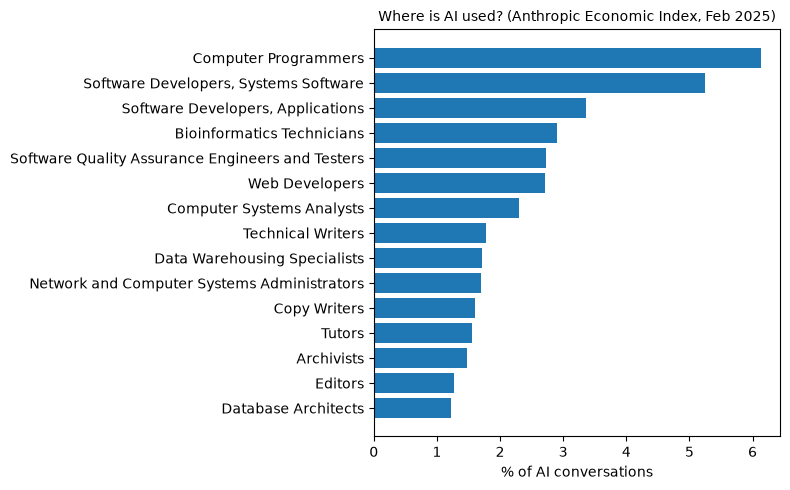

In [4]:
top = by_job.head(15)[::-1]
plt.figure(figsize=(8, 5)); plt.barh(top.index, top.values); plt.xlabel("% of AI conversations")
plt.title("Where is AI used? (Anthropic Economic Index, Feb 2025)", fontsize=10); plt.tight_layout(); plt.show()

## 문제 정형화 연습: '활용사례 발굴' 을 다섯 칸으로

이 노트북은 모델을 학습하지 않는다. 대신 컨설팅 질문을 데이터 문제로 바꿔 보는 연습이다.

- '어느 부서부터 AI 를 도입할까?' → 한 행 = 부서의 업무, y = ? (지금 쓰는 비율? 절약되는 시간? 실수의 비용?)
- 이 데이터의 y 는 '사람들이 실제로 많이 쓰는 곳' 이다. '써야 하는 곳' 이나 '쓰면 이익이 큰 곳' 과 같을까?
- **거버넌스**: 많이 쓰이는 업무일수록 실수했을 때의 위험도 크다. '위험' 을 숫자로 정한다면 무엇을 세야 할까? (참고: AI Incident Database)
- **검증**: 우리 회사에서 고른 활용사례가 맞았는지는 무엇으로 확인할까? 도입 전 · 후로 무엇을 재야 할까?

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |